# Session 1 (Handwriting): frontal channels, segment 1 vs segment 2

The recording was paused once for an impedance check, so it has **two segments**, treated
here as two separate tasks. Each segment is loaded and filtered **on its own** so the jump
at the break doesn't leak into the filtered signal.

Channels: Fp1, Fp2, F9, F7, F3, Fz, F4, F8, F10, sampled at 500 Hz, every sample plotted.
Segment 1 is on the left and segment 2 on the right.

1. Original (unfiltered) data
2. Alpha band, 8–13 Hz (high-pass 8 Hz + low-pass 13 Hz)
3. Gamma band, 30–100 Hz (high-pass 30 Hz + low-pass 100 Hz), with a 60 Hz notch for US mains noise
4. Between alpha and gamma, 13–30 Hz (beta band): alpha and gamma removed

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Make the repo root importable when running from notebooks/
REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "processing").is_dir():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from processing import load_session

SESSION_DIR = REPO_ROOT / "data" / "Session 1_ Handwriting"
F_CHANNELS = ["Fp1", "Fp2", "F9", "F7", "F3", "Fz", "F4", "F8", "F10"]

In [2]:
session = load_session(SESSION_DIR)
assert session.sfreq == 500, session.sfreq

# Keep only the frontal channels in each segment
segments = [seg.copy().pick(F_CHANNELS) for seg in session.segments]

for i, (info, seg) in enumerate(zip(session.segment_info, segments), start=1):
    print(f"Segment {i}: {seg.n_times} samples = {seg.times[-1]:.2f} s, started {info.start_time} UTC")

Segment 1: 74584 samples = 149.17 s, started 2026-11-07 19:54:41.517353 UTC
Segment 2: 101792 samples = 203.58 s, started 2026-11-07 19:57:57 UTC


In [3]:
def plot_segments(segs, title, sharey_rows=True):
    """Grid of channels (rows) x segments (columns), every sample plotted, in µV."""
    n_rows = len(F_CHANNELS)
    fig, axes = plt.subplots(
        n_rows, 2, figsize=(18, 2.2 * n_rows), sharex="col",
        sharey="row" if sharey_rows else False, squeeze=False,
    )
    for col, seg in enumerate(segs):
        data = seg.get_data(picks=F_CHANNELS) * 1e6  # V -> µV
        t = seg.times
        for row, ch in enumerate(F_CHANNELS):
            ax = axes[row, col]
            ax.plot(t, data[row], lw=0.3, color="C0", rasterized=True)
            ax.set_ylabel(f"{ch}\n(µV)", rotation=0, ha="right", va="center")
            ax.margins(x=0)
            ax.grid(alpha=0.3)
        axes[0, col].set_title(f"Segment {col + 1}  ({seg.times[-1]:.1f} s, {seg.n_times} samples)")
        axes[-1, col].set_xlabel("Time from segment start (s)")
    fig.suptitle(title, fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    plt.show()

## 1. Original data

The raw eego signal sits on large, slowly drifting offsets (mV range), so each panel gets
its own y-axis here.

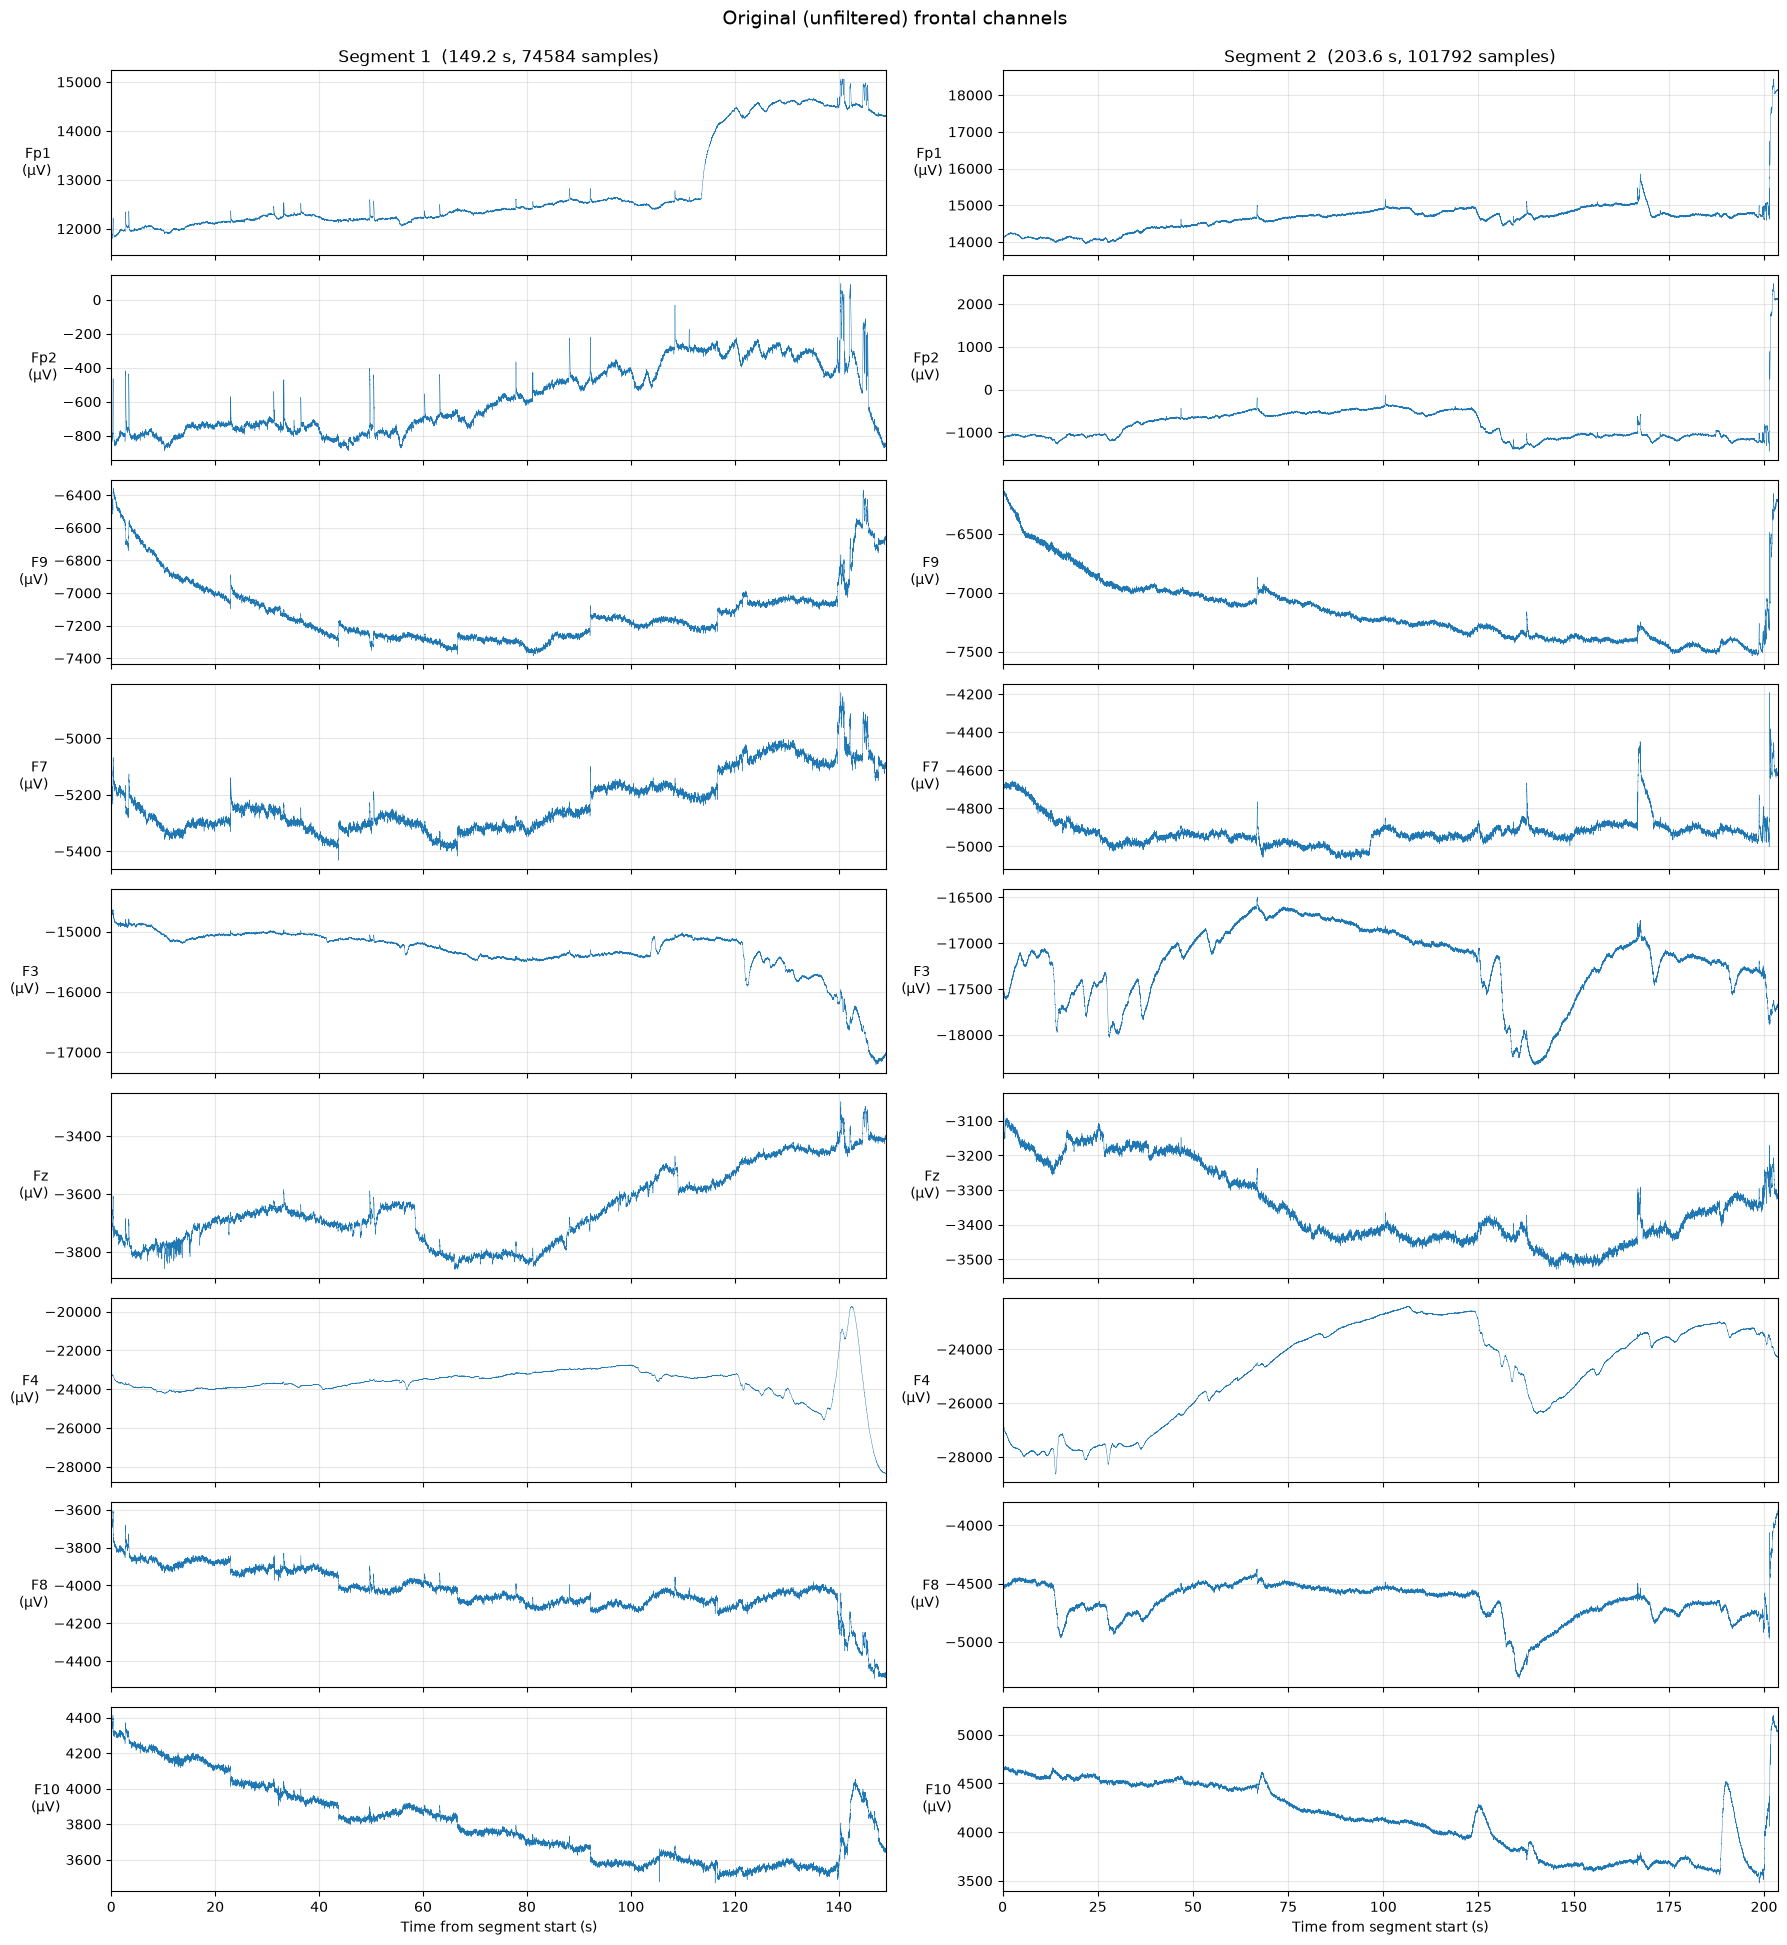

In [4]:
plot_segments(segments, "Original (unfiltered) frontal channels", sharey_rows=False)

## 2. Alpha band (8–13 Hz)

A band-pass is a high-pass at 8 Hz combined with a low-pass at 13 Hz; MNE's
`filter(l_freq=8, h_freq=13)` applies both (zero-phase FIR). The two segments share a
y-axis per channel so their amplitudes can be compared.

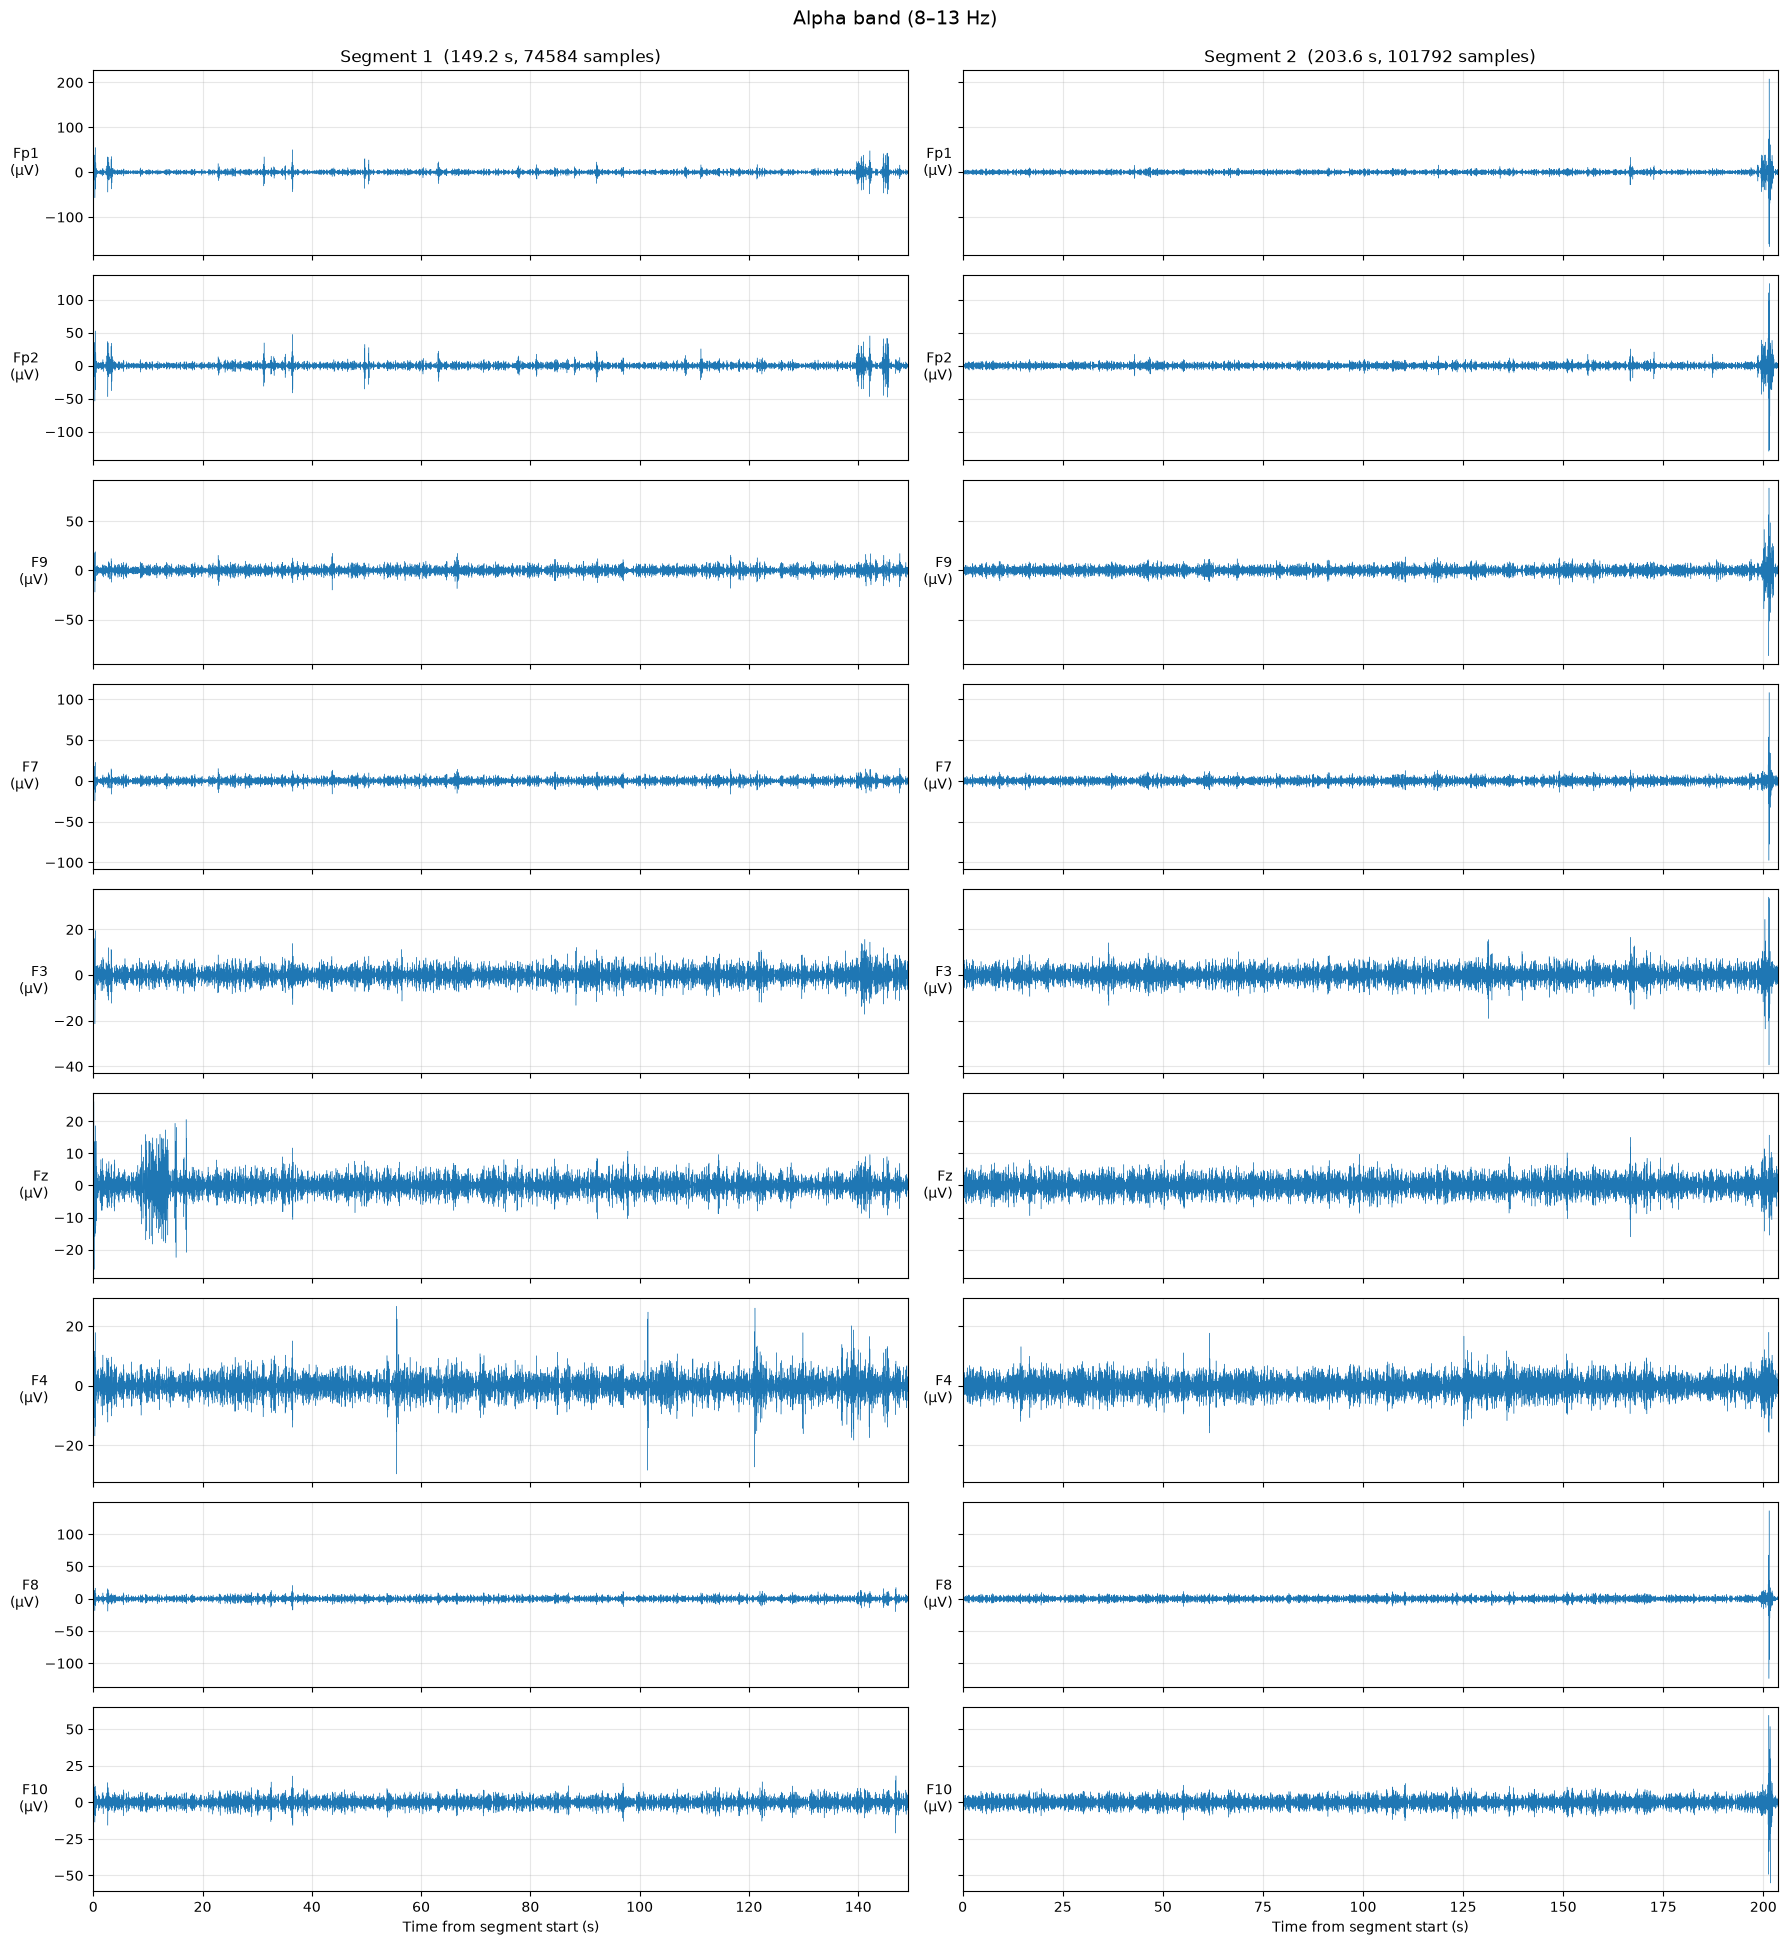

In [5]:
alpha = [seg.copy().filter(l_freq=8.0, h_freq=13.0, verbose="error") for seg in segments]
plot_segments(alpha, "Alpha band (8–13 Hz)")

## 3. Gamma band (30–100 Hz)

High-pass 30 Hz + low-pass 100 Hz. The 60 Hz mains frequency (US) falls inside this band
and would otherwise dominate it, so it is notched out first. Gamma at the frontal
electrodes overlaps strongly with muscle (EMG) activity: forehead tension, jaw clenching
and eye movements, which matter for a handwriting task.

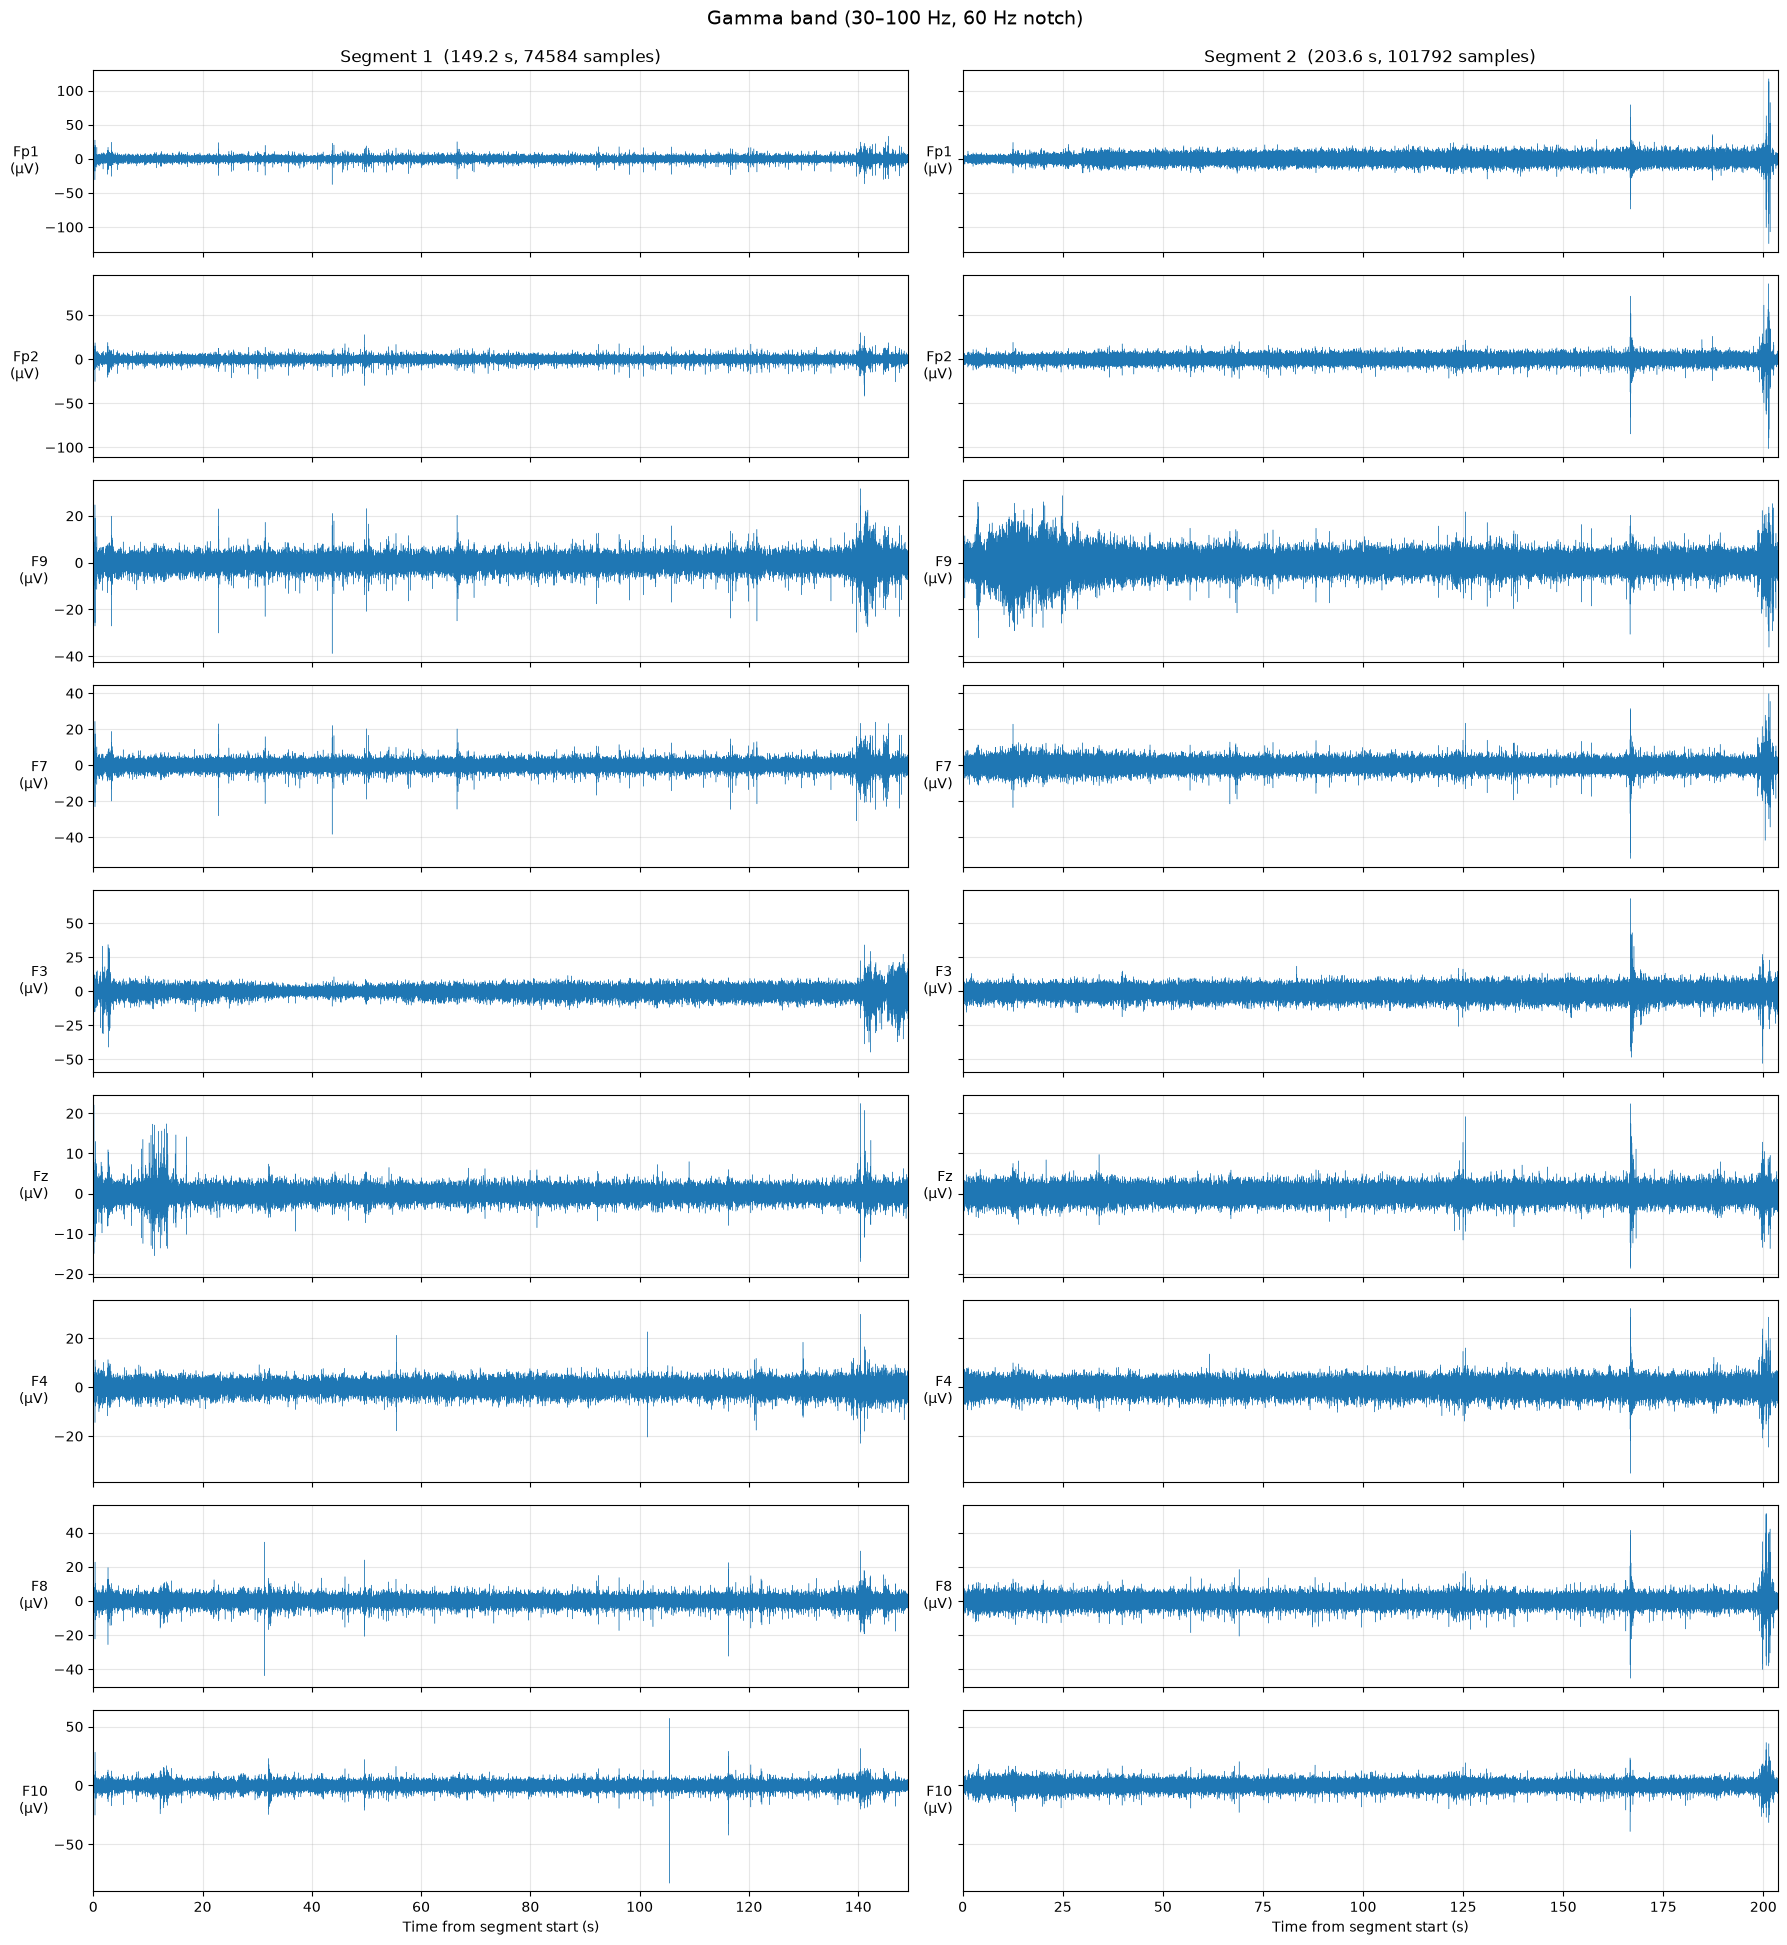

In [6]:
gamma = [
    seg.copy()
    .notch_filter(freqs=60.0, verbose="error")
    .filter(l_freq=30.0, h_freq=100.0, verbose="error")
    for seg in segments
]
plot_segments(gamma, "Gamma band (30–100 Hz, 60 Hz notch)")

## 4. Between alpha and gamma: 13–30 Hz (beta band)

Removes the alpha band and everything below it with a 13 Hz high-pass, and the gamma band
and everything above it with a 30 Hz low-pass, so only 13–30 Hz remains. This range is the
**beta** band, which is linked to active concentration and motor activity, so it's
relevant to handwriting. Beta is strongest over the motor cortex (C3/C4), not the frontal
channels plotted here. Frontal beta can still pick up some muscle activity.

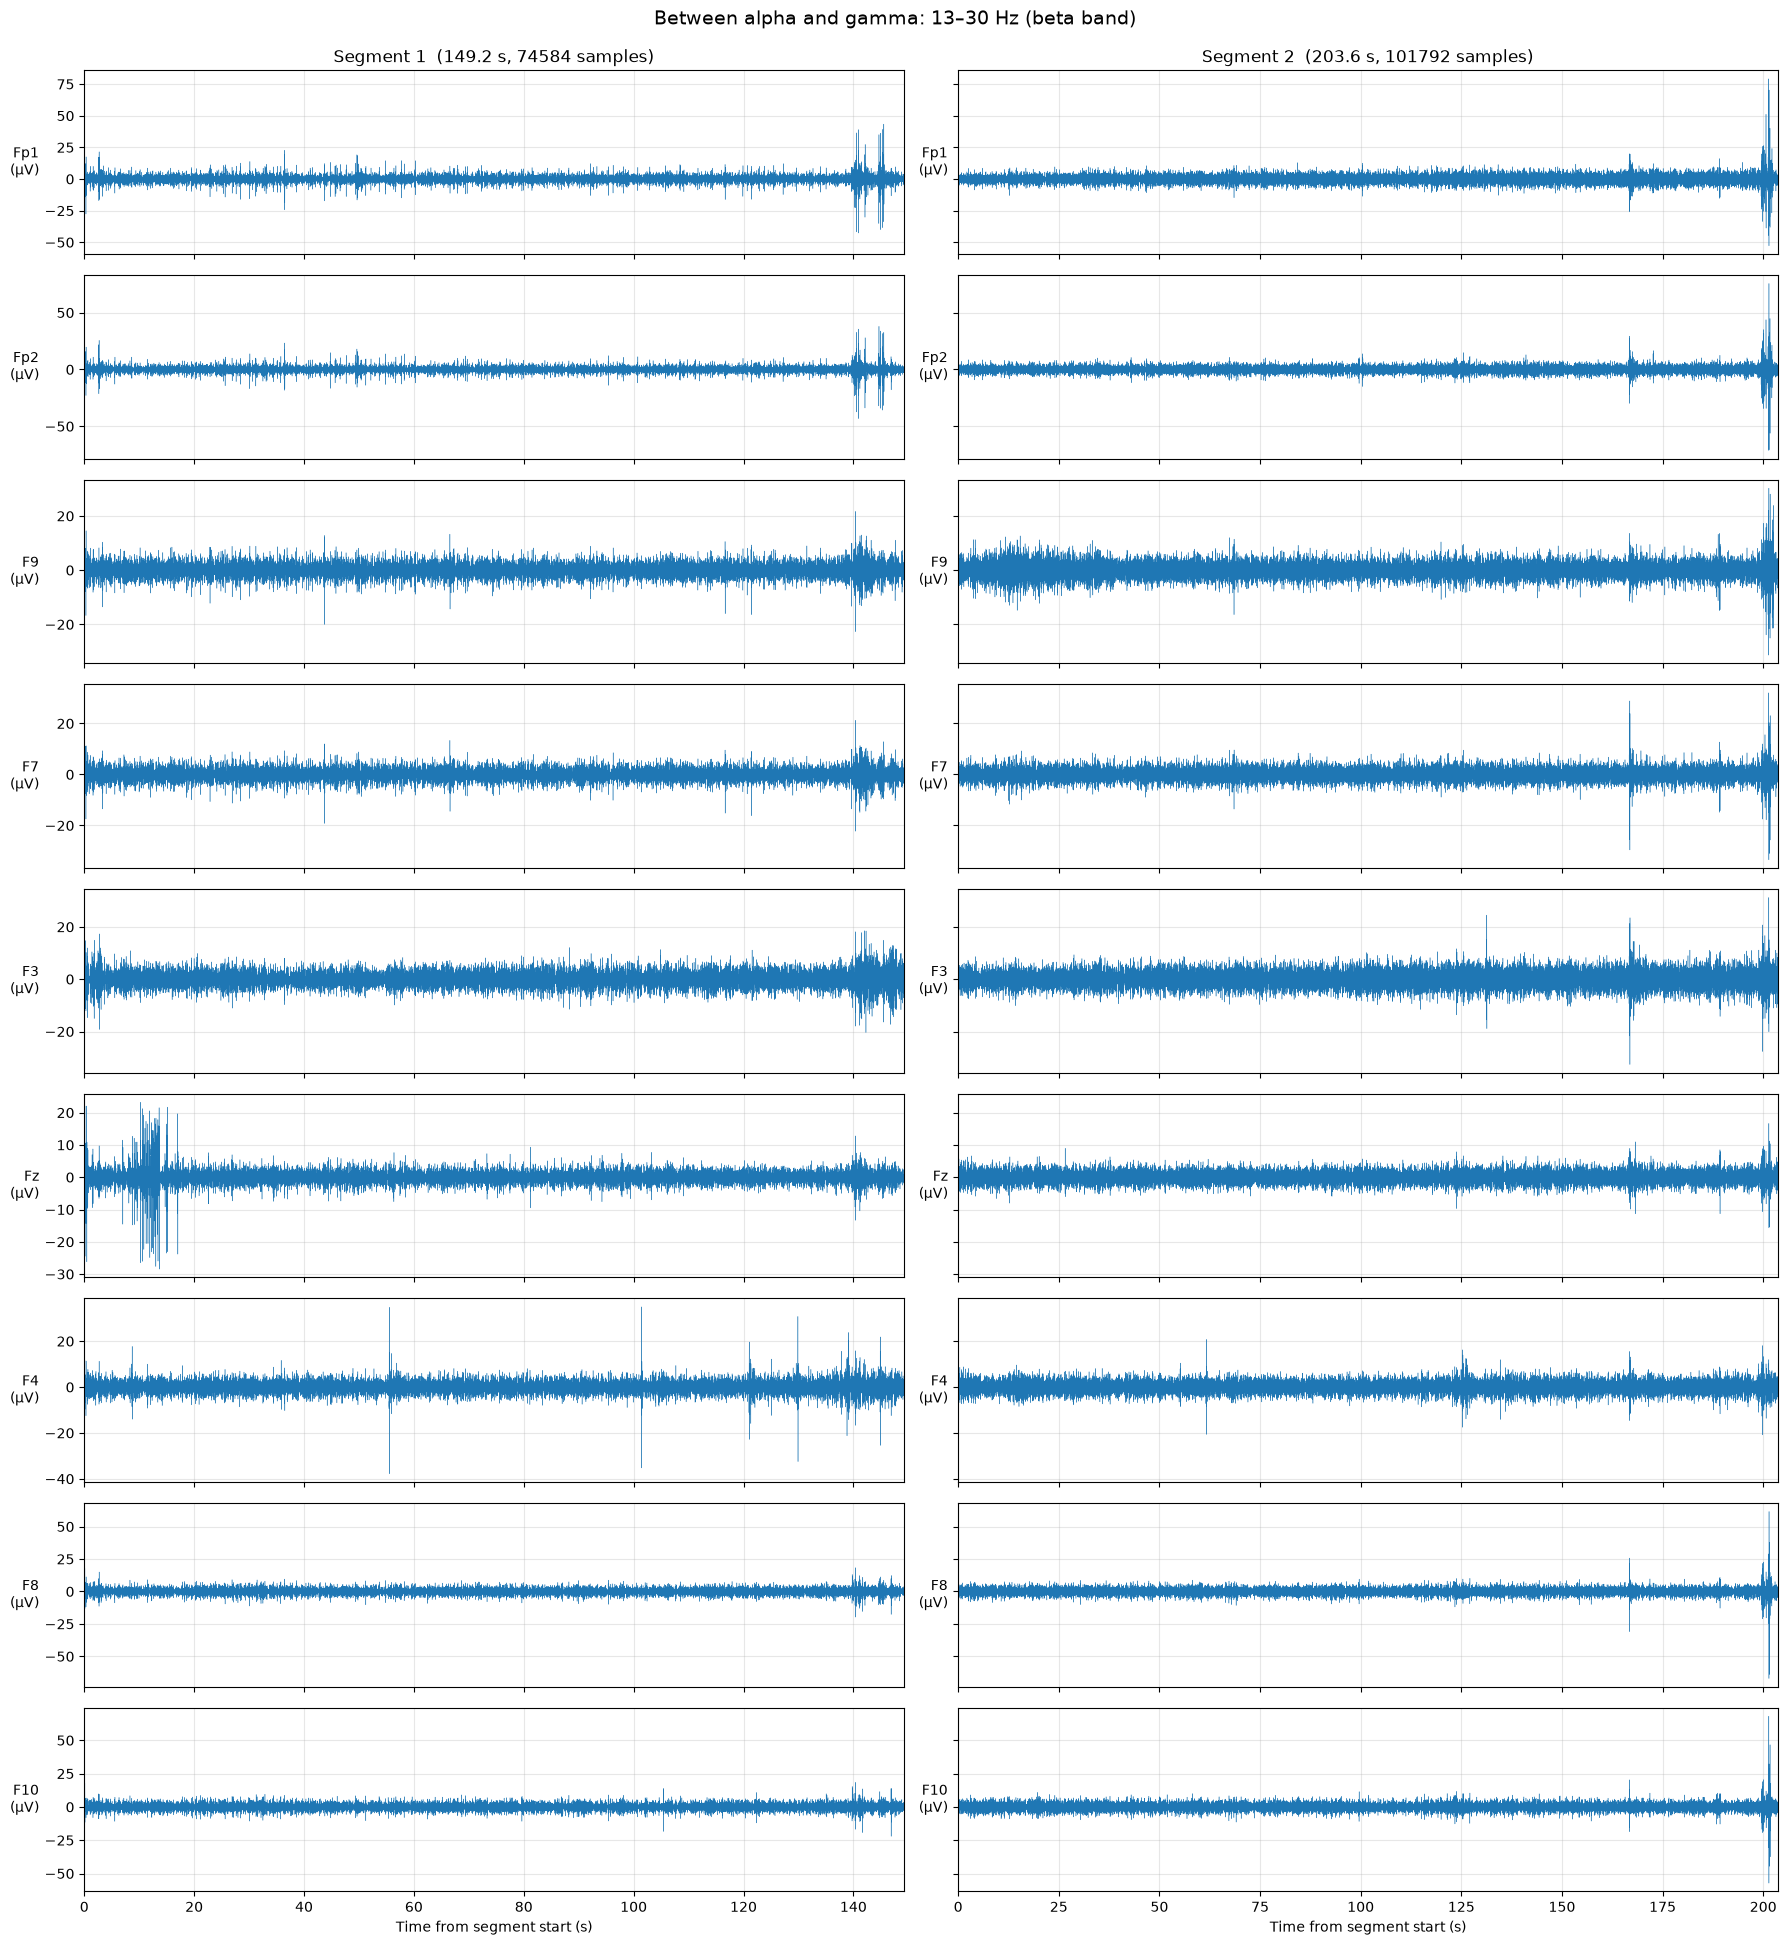

In [7]:
beta = [seg.copy().filter(l_freq=13.0, h_freq=30.0, verbose="error") for seg in segments]
plot_segments(beta, "Between alpha and gamma: 13–30 Hz (beta band)")